# Proyek Analisis Data: E Commerce Public Dataset
- **Nama:** Axel Antonia
- **Email:** axel.antonia20@gmail.com
- **ID Dicoding:** DS244B6Y1850

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

  - **Pertanyaan 1:** Negara bagian (state) mana saja
  yang menjadi 5 wilayah dengan jumlah order dan total revenue (price) tertinggi pada order berstatus delivered selama periode Januari 2017 - Agustus 2018, dan berapa persen kontribusi masing-masing terhadap total order dan total revenue?

  - **Pertanyaan 2:** Berapa selisih rata-rata review_score antara order yang terlambat (tanggal diterima pelanggan melewati tanggal estimasi) dan order yang tepat waktu pada order berstatus delivered selama periode Januari 2017 - Agustus 2018, serta berapa persen order yang mengalami keterlambatan?

## Import Semua Packages/Library yang Digunakan

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

In [4]:
customers_df = pd.read_csv("customers_dataset.csv")
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
geolocation_df = pd.read_csv("geolocation_dataset.csv")
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [6]:
order_items_df = pd.read_csv("order_items_dataset.csv")
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [7]:
order_payments_df = pd.read_csv("order_payments_dataset.csv")
order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [8]:
order_reviews_df = pd.read_csv("order_reviews_dataset.csv")
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [9]:
orders_df = pd.read_csv("orders_dataset.csv")
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
product_category_df = pd.read_csv("product_category_name_translation.csv")
product_category_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [11]:
products_df = pd.read_csv("products_dataset.csv")
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [12]:
sellers_df = pd.read_csv("sellers_dataset.csv")
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


### Assessing Data

**customer_df**

In [13]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [14]:
customers_df.isna().sum()

,0
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


In [15]:
print("Jumlah duplikasi: ", customers_df.duplicated().sum())

Jumlah duplikasi:  0


In [16]:
customers_df.describe()

,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000


**Steps to Take:**
- Tidak diperlukan pembersihan.

**Insight:**
- Tipe data sesuai, tidak ada missing value, tidak ada duplikasi, dan ringkasan statistik tidak menunjukkan keanehan.

**geolocation_df**

In [17]:
geolocation_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [18]:
geolocation_df.isna().sum()

,0
geolocation_zip_code_prefix,0
geolocation_lat,0
geolocation_lng,0
geolocation_city,0
geolocation_state,0


In [19]:
print("Jumlah duplikasi: ", geolocation_df.duplicated().sum())

Jumlah duplikasi:  261831


In [20]:
geolocation_df.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02


**Steps to Take:**
- Hapus data duplikat menggunakan drop_duplicates().
- Hapus data dengan koordinat di luar wilayah Brazil menggunakan drop() berdasarkan kondisi batas wilayah.

**Insight:**
- Duplicate data: terdapat 261.831 baris data yang duplikat.
- Inaccurate value: dataset ini berisi lokasi di Brazil yang seharusnya memiliki latitude sekitar -33,75 hingga 5,27 dan longitude sekitar -73,99 hingga -34,78. Namun, latitude berkisar dari -36,61 hingga 45,07 dan longitude dari -101,47 hingga 121,11, sehingga ada data di luar rentang wilayah Brazil.
- Tidak ada missing value.

**order_items_df**

In [21]:
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [22]:
order_items_df.isna().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


In [23]:
print("Jumlah duplikasi: ", order_items_df.duplicated().sum())

Jumlah duplikasi:  0


In [24]:
order_items_df.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


**Steps to Take:**
- Ubah tipe data kolom shipping_limit_date menjadi datetime menggunakan to_datetime().
- Outlier pada price dan freight_value dipertahankan karena merupakan harga barang dan ongkos kirim yang tinggi, bukan kesalahan input.

**Insight:**
- Tipe data salah: kolom shipping_limit_date bertipe object, seharusnya datetime.
- Outlier: nilai maksimum price (6.735) jauh di atas rata-rata (120,65) dan kuartil ketiga (134,9). Nilai maksimum freight_value (409,68) juga jauh di atas rata-rata (19,99).
- Tidak ada missing value dan tidak ada duplikasi.

**order_payment_df**

In [25]:
order_payments_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [26]:
order_payments_df.isna().sum()

,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [27]:
print("Jumlah duplikasi: ", order_payments_df.duplicated().sum())

Jumlah duplikasi:  0


In [28]:
order_payments_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


**Steps to Take:**
- Ganti payment_installments bernilai 0 menjadi 1 menggunakan replace().
- Hapus baris dengan payment_value bernilai 0 menggunakan drop().
- Outlier pada payment_value dipertahankan karena kemungkinan pembelian bernilai besar.

**Insight:**
- Invalid value: nilai minimum payment_installments adalah 0 (cicilan seharusnya minimal 1) dan nilai minimum payment_value juga 0.
- Outlier: nilai maksimum payment_value (13.664,08) jauh di atas rata-rata (154,10).
- Tidak ada missing value dan tidak ada duplikasi.

**order_reviews_df**

In [29]:
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [30]:
order_reviews_df.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [31]:
print("Jumlah duplikasi: ", order_reviews_df.duplicated().sum())

Jumlah duplikasi:  0


In [32]:
order_reviews_df.describe()

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


**Steps to Take:**
- Ubah kolom review_creation_date dan review_answer_timestamp menjadi datetime.
- Isi missing value pada kolom komentar menggunakan fillna().

**Insight:**
- Tipe data salah: review_creation_date dan review_answer_timestamp bertipe object.
- Missing value: 87.656 pada review_comment_title dan 58.247 pada review_comment_message. Komentar bersifat opsional sehingga wajar kosong.
- Tidak ada duplikasi. Nilai review_score berada pada rentang 1 sampai 5.

**orders_df**

In [33]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [34]:
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [35]:
print("Jumlah duplikasi: ", orders_df.duplicated().sum())

Jumlah duplikasi:  0


In [36]:
orders_df.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


**Steps to Take:**
- Ubah lima kolom tanggal menjadi datetime menggunakan to_datetime().
- Missing value pada kolom tanggal dipertahankan karena mencerminkan status order.

**Insight:**
- Tipe data salah: order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, dan order_estimated_delivery_date bertipe object.
- Missing value: 160 pada order_approved_at, 1.783 pada order_delivered_carrier_date, dan 2.965 pada order_delivered_customer_date.
- Tidak ada duplikasi.

**product_category_df**

In [37]:
product_category_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [38]:
product_category_df.isna().sum()

,0
product_category_name,0
product_category_name_english,0


In [39]:
print("Jumlah duplikasi: ", product_category_df.duplicated().sum())

Jumlah duplikasi:  0


In [40]:
product_category_df.describe()

,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


**Steps to Take:**
- Tidak diperlukan pembersihan.

**Insight:**
- Tipe data sesuai, tidak ada missing value, dan tidak ada duplikasi.

**products_df**

In [41]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [42]:
products_df.isna().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [43]:
print("Jumlah duplikasi: ", products_df.duplicated().sum())

Jumlah duplikasi:  0


In [44]:
products_df.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


**Steps to Take:**
- Isi missing value kategori dengan "unknown" dan kolom angka dengan nilai median menggunakan fillna().
- Ganti berat produk bernilai 0 dengan median menggunakan replace().
- Ubah kolom angka dari float menjadi integer setelah tidak ada missing value.

**Insight:**
- Missing value: 610 pada product_category_name, product_name_lenght, product_description_lenght, dan product_photos_qty, serta 2 pada product_weight_g, product_length_cm, product_height_cm, dan product_width_cm.
- Invalid value: nilai minimum product_weight_g adalah 0 gram.
- Tipe data tidak sesuai: tujuh kolom angka bertipe float64 padahal berisi bilangan bulat (akibat adanya missing value).
- Tidak ada duplikasi.


**sellers_df**

In [45]:
sellers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [46]:
sellers_df.isna().sum()

,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0


In [47]:
print("Jumlah duplikasi: ", sellers_df.duplicated().sum())

Jumlah duplikasi:  0


In [48]:
sellers_df.describe()

,seller_zip_code_prefix
count,3095.000000
mean,32291.059451
std,32713.453830
min,1001.000000
25%,7093.500000
50%,14940.000000
75%,64552.500000
max,99730.000000


**Steps to Take:**
- Tidak diperlukan pembersihan.

**Insight:**
- Tipe data sesuai, tidak ada missing value, dan tidak ada duplikasi.

### Cleaning Data

**geolocation_df**

In [49]:
geolocation_df.drop_duplicates(inplace=True)

In [50]:
kondisi_lat_lebih_dari = geolocation_df['geolocation_lat'] > 5.27
kondisi_lat_kurang_dari = geolocation_df['geolocation_lat'] < -33.75
kondisi_lng_lebih_dari = geolocation_df['geolocation_lng'] > -34.78
kondisi_lng_kurang_dari = geolocation_df['geolocation_lng'] < -73.99

geolocation_df.drop(geolocation_df[kondisi_lat_lebih_dari].index, inplace=True)
geolocation_df.drop(geolocation_df[kondisi_lat_kurang_dari].index, inplace=True)
geolocation_df.drop(geolocation_df[kondisi_lng_lebih_dari].index, inplace=True)
geolocation_df.drop(geolocation_df[kondisi_lng_kurang_dari].index, inplace=True)

/tmp/ipykernel_424/1803435417.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  geolocation_df.drop(geolocation_df[kondisi_lat_kurang_dari].index, inplace=True)
/tmp/ipykernel_424/1803435417.py:8: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  geolocation_df.drop(geolocation_df[kondisi_lng_lebih_dari].index, inplace=True)
/tmp/ipykernel_424/1803435417.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  geolocation_df.drop(geolocation_df[kondisi_lng_kurang_dari].index, inplace=True)


In [51]:
print("Jumlah duplikasi: ", geolocation_df.duplicated().sum())

Jumlah duplikasi:  0


In [52]:
geolocation_df.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,738299.000000,738299.000000,738299.000000
mean,38315.369127,-21.000206,-46.462059
std,30632.644041,5.883219,4.382774
min,1001.000000,-33.692616,-72.930746
25%,12600.000000,-23.603071,-48.867831
50%,29144.000000,-22.873634,-46.647301
75%,65950.000000,-19.923403,-43.837418
max,99990.000000,4.482242,-34.793685


**order_items**

In [53]:
datetime_columns = ["shipping_limit_date"]

for column in datetime_columns:
    order_items_df[column] = pd.to_datetime(order_items_df[column])

In [54]:
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  object        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  object        
 3   seller_id            112650 non-null  object        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 6.0+ MB


In [55]:
order_items_df[order_items_df.price == order_items_df.price.max()]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,2017-02-16 20:37:36,6735.0,194.31


In [56]:
order_items_df[order_items_df.freight_value == order_items_df.freight_value.max()]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,1,ec31d2a17b299511e7c8627be9337b9b,257e61d3251fb5efb9daadddbc2cf7ca,2018-04-25 06:55:13,979.0,409.68


**Insight:**
- Kolom shipping_limit_date telah diubah menjadi datetime.
- Baris dengan price maksimum (6.735) juga memiliki freight_value yang tinggi (194,31), dan baris dengan freight_value maksimum (409,68) memiliki price yang tinggi (979). Nilai ini konsisten dengan barang mahal atau berat, bukan kesalahan input, sehingga outlier dipertahankan.

**order_payments_df**

In [57]:
order_payments_df[order_payments_df.payment_installments == 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [58]:
order_payments_df['payment_installments'] = order_payments_df['payment_installments'].replace(0, 1)

In [59]:
order_payments_df[order_payments_df.payment_value == 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


In [60]:
payment_value_nol = order_payments_df['payment_value'] == 0
order_payments_df.drop(order_payments_df[payment_value_nol].index, inplace=True)

In [61]:
order_payments_df[order_payments_df.payment_value == order_payments_df.payment_value.max()]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,1,credit_card,1,13664.08


In [62]:
order_payments_df.describe()

,payment_sequential,payment_installments,payment_value
count,103877.000000,103877.000000,103877.000000
mean,1.092340,2.853529,154.113732
std,0.704312,2.687095,217.498755
min,1.000000,1.000000,0.010000
25%,1.000000,1.000000,56.820000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.840000
max,29.000000,24.000000,13664.080000


**Insight:**
- 2 data dengan payment_installments 0 (kartu kredit) diganti dengan 1 karena cicilan minimal 1 kali.
- 9 data dengan payment_value 0 (tipe voucher dan not_defined) dihapus karena bukan transaksi pembayaran.
- Nilai payment_value maksimum (13.664,08) dibayar dengan kartu kredit sehingga kemungkinan merupakan pembelian beberapa barang sekaligus.


**order_reviews.df**

In [63]:
datetime_columns = ["review_creation_date", "review_answer_timestamp"]

for column in datetime_columns:
    order_reviews_df[column] = pd.to_datetime(order_reviews_df[column])

In [64]:
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  object        
 1   order_id                 99224 non-null  object        
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  object        
 4   review_comment_message   40977 non-null  object        
 5   review_creation_date     99224 non-null  datetime64[ns]
 6   review_answer_timestamp  99224 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1), object(4)
memory usage: 5.3+ MB


In [65]:
order_reviews_df.fillna(value={"review_comment_title": "No title", "review_comment_message": "No comment"}, inplace=True)

In [66]:
order_reviews_df.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,0
review_comment_message,0
review_creation_date,0
review_answer_timestamp,0


**Insight:**
- Kolom review_creation_date dan review_answer_timestamp telah diubah menjadi datetime.
- Baris dengan komentar kosong masih memuat review_score yang penting untuk analisis, sehingga tidak dihapus. Missing value diisi "No title" dan "No comment".

**orders_df**

In [67]:
datetime_columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]

for column in datetime_columns:
    orders_df[column] = pd.to_datetime(orders_df[column])

In [68]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [69]:
orders_df[orders_df.order_delivered_customer_date.isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,NaT,2017-05-09
44,ee64d42b8cf066f35eac1cf57de1aa85,caded193e8e47b8362864762a83db3c5,shipped,2018-06-04 16:44:48,2018-06-05 04:31:18,2018-06-05 14:32:00,NaT,2018-06-28
103,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,NaT,NaT,2018-08-21
128,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,NaT,NaT,2017-10-03
154,6942b8da583c2f9957e990d028607019,52006a9383bf149a4fb24226b173106f,shipped,2018-01-10 11:33:07,2018-01-11 02:32:30,2018-01-11 19:39:23,NaT,2018-02-07
...,...,...,...,...,...,...,...,...
99283,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaT,NaT,NaT,2018-10-01
99313,e9e64a17afa9653aacf2616d94c005b8,b4cd0522e632e481f8eaf766a2646e86,processing,2018-01-05 23:07:24,2018-01-09 07:18:05,NaT,NaT,2018-02-06
99347,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaT,NaT,NaT,2018-09-27
99348,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaT,NaT,2017-09-15


In [70]:
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


**Insight:**
- Missing value pada kolom tanggal “hampir seluruhnya berasal dari order yang belum selesai atau dibatalkan, sehingga bagian kosongnya sesuai dengan kondisi order. Mengisinya dengan tanggal buatan akan menghasilkan data yang salah, dan menghapusnya akan membuang banyak order. Karena itu missing value dipertahankan.
- Analisis yang membutuhkan tanggal diterima akan memakai order berstatus delivered.

**products_df**

In [71]:
products_df[products_df.product_category_name.isna()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
...,...,...,...,...,...,...,...,...,...
32515,b0a0c5dd78e644373b199380612c350a,NaN,NaN,NaN,NaN,1800.0,30.0,20.0,70.0
32589,10dbe0fbaa2c505123c17fdc34a63c56,NaN,NaN,NaN,NaN,800.0,30.0,10.0,23.0
32616,bd2ada37b58ae94cc838b9c0569fecd8,NaN,NaN,NaN,NaN,200.0,21.0,8.0,16.0
32772,fa51e914046aab32764c41356b9d4ea4,NaN,NaN,NaN,NaN,1300.0,45.0,16.0,45.0


In [72]:
products_df.fillna(value={
    "product_category_name": "unknown",
    "product_name_lenght": products_df.product_name_lenght.median(),
    "product_description_lenght": products_df.product_description_lenght.median(),
    "product_photos_qty": products_df.product_photos_qty.median(),
    "product_weight_g": products_df.product_weight_g.median(),
    "product_length_cm": products_df.product_length_cm.median(),
    "product_height_cm": products_df.product_height_cm.median(),
    "product_width_cm": products_df.product_width_cm.median()
}, inplace=True)

In [73]:
products_df[products_df.product_weight_g == 0]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


In [74]:
products_df['product_weight_g'] = products_df['product_weight_g'].replace(0, products_df['product_weight_g'].median())

In [75]:
int_columns = ["product_name_lenght", "product_description_lenght", "product_photos_qty","product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]

for column in int_columns:
    products_df[column] = products_df[column].astype(int)

In [76]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   product_id                  32951 non-null  object
 1   product_category_name       32951 non-null  object
 2   product_name_lenght         32951 non-null  int64 
 3   product_description_lenght  32951 non-null  int64 
 4   product_photos_qty          32951 non-null  int64 
 5   product_weight_g            32951 non-null  int64 
 6   product_length_cm           32951 non-null  int64 
 7   product_height_cm           32951 non-null  int64 
 8   product_width_cm            32951 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 2.3+ MB


In [77]:
products_df.isna().sum()

,0
product_id,0
product_category_name,0
product_name_lenght,0
product_description_lenght,0
product_photos_qty,0
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


In [78]:
products_df.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32951.000000,32951.000000,32951.000000,32951.000000,32951.000000,32951.000000,32951.000000
mean,48.523656,768.227945,2.166975,2276.461777,30.814725,16.937422,23.196534
std,10.156155,629.658469,1.728063,4281.888156,16.914005,13.637175,12.078707
min,5.000000,4.000000,1.000000,2.000000,7.000000,2.000000,6.000000
25%,42.000000,344.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,961.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


**Insight:**
- Baris dengan kategori kosong masih memiliki berat dan dimensi produk sehingga tidak dihapus. Kategori diisi "unknown" agar tidak dianggap kategori tertentu, sedangkan kolom angka diisi median karena tidak terpengaruh nilai ekstrem.
- 4 produk berat 0 gram diganti dengan median berat produk.
- Setelah tidak ada missing value, 7 kolom angka diubah menjadi integer.

## Exploratory Data Analysis (EDA)

**Explore orders_df: status dan jumlah order per bulan**

In [79]:
orders_df.groupby(by="order_status").order_id.nunique().sort_values(ascending=False)

,order_id
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [80]:
orders_df["order_month"] = orders_df.order_purchase_timestamp.apply(lambda x: x.strftime("%Y-%m"))
orders_df.groupby(by="order_month").order_id.nunique()

,order_id
order_month,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


**Insight:**
- Terdapat 96.478 berstatus delivered. Sisanya masih dikirim, dibatalkan, atau belum tersedia.
- Order tahun 2016 hanya 1 sampai 324 per bulan, dan pada September-Oktober 2018 hanya 16 dan 4 order. Sementara Januari 2017 sampai Agustus 2018 berisi 800 sampai 7.544 order per bulan

**Explore orders_df: filter order delivered dan waktu pengiriman**

In [83]:
orders_delivered_df = orders_df[(orders_df.order_status == "delivered") & (orders_df.order_purchase_timestamp >= "2017-01-01") & (orders_df.order_purchase_timestamp < "2018-09-01")]

In [85]:
print("Jumlah order: ", orders_delivered_df.order_id.nunique())
print("Order tanpa tanggal diterima: ", orders_delivered_df.order_delivered_customer_date.isna().sum())

Jumlah order:  96211
Order tanpa tanggal diterima:  8


In [86]:
orders_delivered_df = orders_delivered_df.dropna(subset=["order_delivered_customer_date"]).copy()

orders_delivered_df["delivery_time"] = ((orders_delivered_df["order_delivered_customer_date"] - orders_delivered_df["order_purchase_timestamp"]) / pd.Timedelta(days=1)).round()

orders_delivered_df["delay_days"] = (orders_delivered_df["order_delivered_customer_date"] - orders_delivered_df["order_estimated_delivery_date"]) / pd.Timedelta(days=1)

orders_delivered_df[["delivery_time", "delay_days"]].describe()

,delivery_time,delay_days
count,96203.000000,96203.000000
mean,12.497147,-11.109930
std,9.533985,10.090530
min,1.000000,-146.016123
25%,7.000000,-16.224630
50%,10.000000,-11.817523
75%,16.000000,-6.380764
max,210.000000,188.975081


**insight**
- Rata-rata waktu pengiriman adalah 12,5 hari, dengan nilai maksimum 210 hari.
- Rata-rata delay_days bernilai -11,1 hari, artinya paket tiba sekitar 11 hari lebih cepat dari estimasi. Max keterlambatan hingga mencapai 189 hari.

Explore orders_df dan customers_df

In [87]:
orders_customers_df = pd.merge(
    left=orders_delivered_df,
    right=customers_df,
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)
orders_customers_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_month,delivery_time,delay_days,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,8.0,-7.107488,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,14.0,-5.355729,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,9.0,-17.245498,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,13.0,-12.980069,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,3.0,-9.238171,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [88]:
orders_customers_df.groupby(by="customer_state").order_id.nunique().sort_values(ascending=False)

,order_id
customer_state,
SP,40399
RJ,12310
MG,11319
RS,5327
PR,4903
SC,3537
BA,3253
DF,2074
ES,1992


**Insight:**
- Pelanggan berasal dari 27 negara bagian.
- Lima negara bagian dengan order terbanyak adalah SP (40.399), RJ (12.310), MG (11.319), RS (5.327), dan PR (4.903).

Explore all_df

In [89]:
all_df = pd.merge(
    left=orders_customers_df,
    right=order_items_df,
    how="left",
    left_on="order_id",
    right_on="order_id"
)
all_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_month,delivery_time,...,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,8.0,...,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,14.0,...,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,9.0,...,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,13.0,...,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,3.0,...,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [90]:
state_df = all_df.groupby(by="customer_state").agg({
    "order_id": "nunique",
    "price": "sum"
}).reset_index()

state_df.rename(columns={"order_id": "order_count", "price": "revenue"}, inplace=True)
state_df["order_pct"] = round(state_df.order_count / state_df.order_count.sum() * 100, 2)
state_df["revenue_pct"] = round(state_df.revenue / state_df.revenue.sum() * 100, 2)

state_df.sort_values(by="revenue", ascending=False).head(5)

,customer_state,order_count,revenue,order_pct,revenue_pct
25,SP,40399,5054516.95,41.99,38.35
18,RJ,12310,1751433.85,12.80,13.29
10,MG,11319,1548206.88,11.77,11.75
22,RS,5327,726194.92,5.54,5.51
17,PR,4903,664048.00,5.10,5.04


In [91]:
state_df.sort_values(by="revenue", ascending=True).head(5)

,customer_state,order_count,revenue,order_pct,revenue_pct
21,RR,40,7017.77,0.04,0.05
3,AP,67,13374.81,0.07,0.10
0,AC,80,15930.97,0.08,0.12
2,AM,145,22155.84,0.15,0.17
20,RO,243,45682.76,0.25,0.35


**insight**
- SP adalah negara bagian dengan kontribusi terbesar: 41,99% dari total order dan 38,35% dari total revenue (5.054.516,95).
- Lima negara bagian dengan revenue terendah adalah RR, AP, AC, AM, dan RO, masing-masing hanya 0,05% sampai 0,35% dari total revenue.

Explore orders_reviews_df

In [92]:
review_per_order_df = order_reviews_df.groupby(by="order_id").review_score.mean().reset_index()

orders_reviews_df = pd.merge(
    left=orders_delivered_df,
    right=review_per_order_df,
    how="left",
    left_on="order_id",
    right_on="order_id"
)

orders_reviews_df["delivery_status"] = orders_reviews_df.delay_days.apply(lambda x: "Late" if x > 0 else "On Time")
orders_reviews_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_month,delivery_time,delay_days,review_score,delivery_status
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,8.0,-7.107488,4.0,On Time
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,14.0,-5.355729,4.0,On Time
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,9.0,-17.245498,5.0,On Time
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,13.0,-12.980069,5.0,On Time
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,3.0,-9.238171,5.0,On Time


In [94]:
print("Order tanpa review: ", orders_reviews_df.review_score.isna().sum())

Order tanpa review:  643


In [95]:
orders_reviews_df.groupby(by="delivery_status").agg({
    "order_id": "nunique",
    "review_score": ["mean", "min", "max"],
    "delay_days": "mean"
})

order_id review_score           delay_days
                 nunique         mean  min  max       mean
delivery_status                                           
Late                7822     2.566728  1.0  5.0   9.549353
On Time            88381     4.295086  1.0  5.0 -12.938343

In [96]:
order_count = orders_reviews_df.groupby(by="delivery_status").order_id.nunique()
round(order_count / order_count.sum() * 100, 2)

,order_id
delivery_status,
Late,8.13
On Time,91.87


In [97]:
orders_reviews_df[orders_reviews_df.delivery_status == "Late"].delay_days.describe()

,delay_days
count,7822.000000
mean,9.549353
std,13.951750
min,0.002500
25%,1.867269
50%,5.806481
75%,11.820336
max,188.975081


- Rata-rata review_score order tepat waktu adalah 4,30, sedangkan order terlambat hanya 2,57. Selisihnya 1,73 poin.
- Order yang terlambat rata-rata datang 9,5 hari setelah estimasi (median 5,8 hari), dengan keterlambatan terparah mencapai 189 hari.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Negara bagian mana saja yang menjadi 5 wilayah dengan jumlah order dan total revenue tertinggi, dan berapa persen kontribusinya?

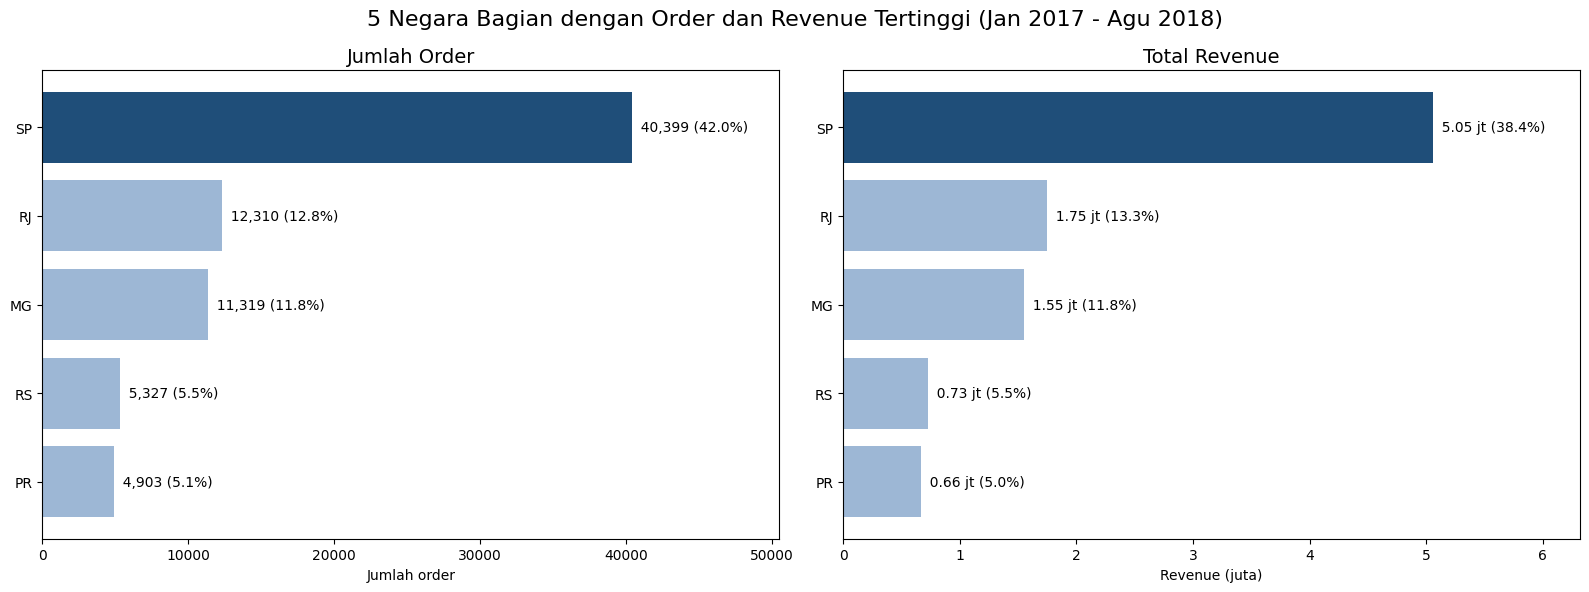

In [113]:
top5_df = state_df.sort_values(by="revenue", ascending=False).head(5)
colors = ["#1F4E79", "#9DB7D5", "#9DB7D5", "#9DB7D5", "#9DB7D5"]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

ax[0].barh(top5_df["customer_state"], top5_df["order_count"], color=colors)
ax[0].set_title("Jumlah Order", fontsize=14)
ax[0].set_xlabel("Jumlah order")
ax[0].invert_yaxis()
for i, (v, p) in enumerate(zip(top5_df["order_count"], top5_df["order_pct"])):
  ax[0].text(v, i, f"  {v:,} ({p:.1f}%)", va="center")
ax[0].set_xlim(0, top5_df["order_count"].max() * 1.25)

ax[1].barh(top5_df["customer_state"], top5_df["revenue"] / 1e6, color=colors)
ax[1].set_title("Total Revenue", fontsize=14)
ax[1].set_xlabel("Revenue (juta)")
ax[1].invert_yaxis()
for i, (v, p) in enumerate(zip(top5_df["revenue"], top5_df["revenue_pct"])):
  ax[1].text(v / 1e6, i, f"  {v/1e6:.2f} jt ({p:.1f}%)", va="center")
ax[1].set_xlim(0, (top5_df["revenue"].max() / 1e6) * 1.25)

fig.suptitle(
    "5 Negara Bagian dengan Order dan Revenue Tertinggi (Jan 2017 - Agu 2018)",
    fontsize=16,
)
plt.tight_layout()
plt.show()

**Insight:**
- SP adalah negara bagian dengan kontribusi terbesar, yaitu 42,0% dari total order (40.399 order) dan 38,4% dari total revenue (5,05 juta). Angkanya jauh di atas negara bagian lain.
- RJ dan MG berada di posisi kedua dan ketiga dengan kontribusi sekitar 12-13% order dan 12-13% revenue. RS dan PR masing-masing sekitar 5%.
- Lima negara bagian teratas menyumbang 77,2% order dan 73,9% revenue, sehingga penjualan sangat terpusat di wilayah tenggara dan selatan.

### Pertanyaan 2: Berapa selisih rata-rata review score antara order terlambat dan tepat waktu, serta berapa persen order yang terlambat?

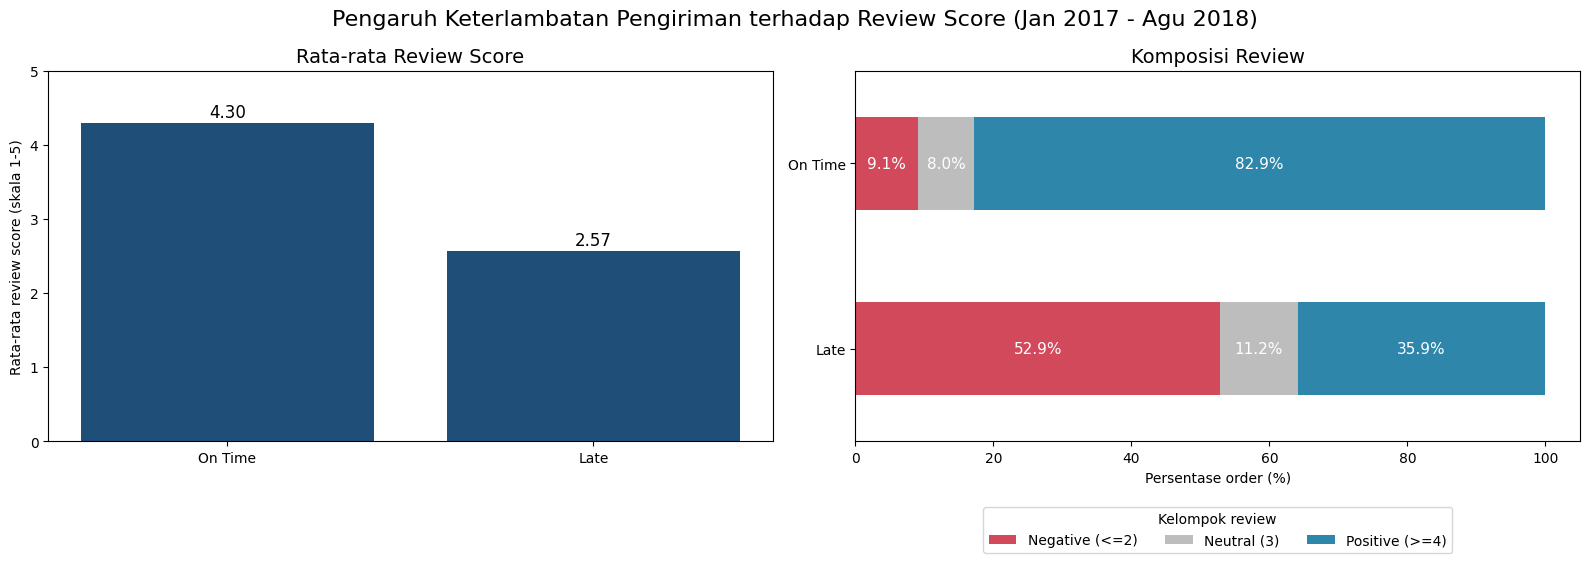

In [115]:
status_df = (
    orders_reviews_df.groupby(by="delivery_status")
    .review_score.mean()
    .reset_index()
)
status_df = status_df.sort_values(by="review_score", ascending=False)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

ax[0].bar(status_df["delivery_status"], status_df["review_score"], color="#1F4E79")
ax[0].set_title("Rata-rata Review Score", fontsize=14)
ax[0].set_ylabel("Rata-rata review score (skala 1-5)")
ax[0].set_ylim(0, 5)
for i, v in enumerate(status_df["review_score"]):
  ax[0].text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=12)

review_group_df = (
    orders_reviews_df.groupby(by=["delivery_status", "review_group"])
    .order_id.nunique()
    .unstack()
)
review_group_pct_df = (
    review_group_df.div(review_group_df.sum(axis=1), axis=0) * 100
)

review_group_pct_df.plot(
    kind="barh", stacked=True, ax=ax[1], color=["#D1495B", "#BDBDBD", "#2E86AB"]
)
ax[1].set_title("Komposisi Review", fontsize=14)
ax[1].set_xlabel("Persentase order (%)")
ax[1].set_ylabel("")
ax[1].legend(
    title="Kelompok review",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.32),
    ncol=3,
)
for container in ax[1].containers:
  ax[1].bar_label(
      container, fmt="%.1f%%", label_type="center", color="white", fontsize=11
  )

fig.suptitle(
    "Pengaruh Keterlambatan Pengiriman terhadap Review Score (Jan 2017 - Agu"
    " 2018)",
    fontsize=16,
)
plt.tight_layout()
plt.show()

**Insight:**
- Rata-rata review score order tepat waktu adalah 4,30, sedangkan order terlambat turun menjadi 2,57 (selisih 1,73 poin).
- Meski hanya 8,13% order (7.822 dari 96.203 order) yang terlambat, dampaknya sangat besar terhadap kepuasan pelanggan.
- Saat order terlambat, review negatif melonjak dari 9,1% menjadi 52,9%, sedangkan review positif turun drastis dari 82,9% menjadi 35,9%.

## Analisis Lanjutan (Opsional)

**Tujuan:** Mengelompokkan tingkat keterlambatan pengiriman (*manual grouping*) berdasarkan variabel delay_days untuk mengetahui seberapa besar penurunan kepuasan pelanggan (*review_score*) seiring bertambahnya durasi keterlambatan paket.

In [106]:
def categorize_delay(days):
    if days <= 0:
        return "1. Tepat Waktu (<= 0 hari)"
    elif days <= 3:
        return "2. Terlambat Ringan (1-3 hari)"
    elif days <= 7:
        return "3. Terlambat Sedang (4-7 hari)"
    else:
        return "4. Terlambat Berat (> 7 hari)"

orders_reviews_df["delay_category"] = orders_reviews_df["delay_days"].apply(categorize_delay)

In [107]:
delay_cluster_df = orders_reviews_df.groupby("delay_category").agg({
    "order_id": "nunique",
    "review_score": "mean"
}).reset_index()

delay_cluster_df.rename(columns={
    "order_id": "total_orders",
    "review_score": "avg_review_score"
}, inplace=True)

delay_cluster_df

,delay_category,total_orders,avg_review_score
0,1. Tepat Waktu (<= 0 hari),88381,4.295086
1,2. Terlambat Ringan (1-3 hari),2660,3.766793
2,3. Terlambat Sedang (4-7 hari),1819,2.317259
3,4. Terlambat Berat (> 7 hari),3343,1.729846


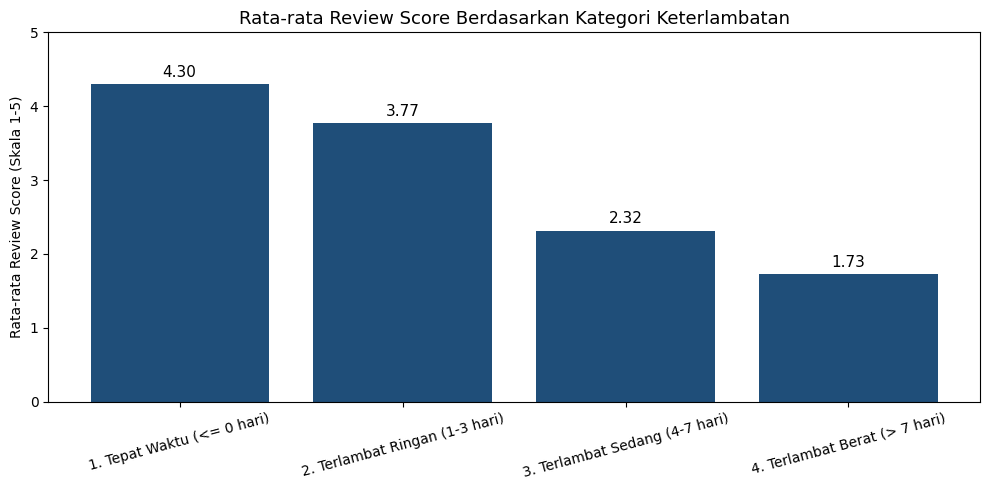

In [117]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    delay_cluster_df["delay_category"],
    delay_cluster_df["avg_review_score"],
    color="#1F4E79",
)
ax.set_title(
    "Rata-rata Review Score Berdasarkan Kategori Keterlambatan", fontsize=13
)
ax.set_ylabel("Rata-rata Review Score (Skala 1-5)")
ax.set_ylim(0, 5)
plt.xticks(rotation=15)

for bar in bars:
  yval = bar.get_height()
  ax.text(
      bar.get_x() + bar.get_width() / 2,
      yval + 0.1,
      f"{yval:.2f}",
      ha="center",
      fontsize=11,
  )

plt.tight_layout()
plt.show()

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama periode Januari 2017 – Agustus 2018 pada order berstatus delivered, lima negara bagian dengan jumlah order dan total revenue tertinggi adalah SP, RJ, MG, RS, dan PR. SP (São Paulo) menjadi wilayah dengan kontribusi terbesar, yaitu 41,99% dari total order (40.399 order) dan 38,35% dari total revenue (5,05 juta). Posisi berikutnya diikuti oleh RJ (12,80% order; 13,29% revenue), MG (11,77% order; 11,75% revenue), RS (5,54% order; 5,51% revenue), dan PR (5,10% order; 5,04% revenue). Secara keseluruhan, kelima wilayah ini menyumbang lebih dari 77% total order dan 73% total revenue, yang menunjukkan bahwa transaksi sangat terpusat di wilayah tenggara dan selatan Brazil   
- **Conclusion pertanyaan 2:** Pada periode Januari 2017 – Agustus 2018, terdapat 8,13% order (7.822 dari 96.203 order) yang mengalami keterlambatan pengiriman, dengan rata-rata keterlambatan sekitar 9,5 hari dari tanggal estimasi. Keterlambatan ini berdampak besar terhadap kepuasan pelanggan, di mana rata-rata review score pada order yang terlambat hanya mencapai 2,57, jauh lebih rendah dibandingkan order yang tepat waktu sebesar 4,30 (selisih 1,73 poin). Selain itu, pada order yang terlambat, persentase ulasan negatif (skor $\le 2$) melonjak hingga 52,9% dibandingkan hanya 9,1% pada order yang tepat waktu

**Rekomendasi Action Item:**
Pertanyaan 1:
- Perkuat pengiriman dan stok di wilayah utama: Tambah gudang penyimpanan dan perbanyak kerja sama kurir di wilayah SP, RJ, dan MG agar pengiriman di daerah dengan pesanan terbanyak tetap cepat dan lancar.
- Berikan promo ongkir untuk wilayah dengan pesanan rendah: Buat promo khusus atau subsidi ongkos kirim untuk wilayah yang transaksinya masih sedikit (seperti RR, AP, AC, AM, dan RO) agar penjualan lebih merata.

Pertanyaan 2:
- Evaluasi jasa pengiriman dan sistem estimasi: Evaluasi kurir atau rute yang sering telat, perbarui perhitungan estimasi waktu sampai agar lebih akurat, dan kirim pemberitahuan otomatis ke pelanggan jika paket berpotensi terlambat supaya mereka tidak kecewa.

In [104]:
all_data_df = pd.merge(
    left=all_df,
    right=orders_reviews_df[["order_id", "review_score", "delivery_status"]],
    how="left",
    left_on="order_id",
    right_on="order_id"
)

all_data_df.to_csv("main_data.csv", index=False)

In [105]:
from google.colab import files
files.download("main_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>